#Loading Data

In [169]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [170]:
df = pd.read_csv("House_price.csv")
df.head()

,Avg. Area Income,House Age,Number of Rooms,Number of Bedrooms,Area Population,Price,Address
0,79545.45857,5.682861,7.009188,4.09,23086.80050,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64245,6.002900,6.730821,3.09,40173.07217,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.06718,5.865890,8.512727,5.13,36882.15940,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24005,7.188236,5.586729,3.26,34310.24283,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.19723,5.040555,7.839388,4.23,26354.10947,6.309435e+05,USNS Raymond\nFPO AE 09386


In [171]:
df.sample(5)

,Avg. Area Income,House Age,Number of Rooms,Number of Bedrooms,Area Population,Price,Address
1443,74243.74684,6.258816,7.802438,4.27,40328.23344,1.713351e+06,"PSC 6960, Box 0333\nAPO AA 78454-0482"
1024,61868.60746,5.787124,4.774978,3.17,34967.07563,9.748060e+05,"76329 Eric Mount Suite 495\nWhiteville, AS 79813"
1891,101144.32390,6.350845,7.231771,3.09,35772.52401,2.007556e+06,"233 Wilson Ranch Suite 086\nWest Christine, IN..."
3961,62992.19010,5.913663,7.054529,3.27,23116.79338,8.673111e+05,07743 Michael Glens Suite 132\nLake Gabrielash...
2202,77911.35703,5.615810,5.058697,3.04,42795.34656,1.309860e+06,USNV Morris\nFPO AP 49380


In [172]:
df.shape

(4548, 7)

In [173]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4548 entries, 0 to 4547
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Avg. Area Income    4548 non-null   float64
 1   House Age           4548 non-null   float64
 2   Number of Rooms     4548 non-null   float64
 3   Number of Bedrooms  4548 non-null   float64
 4   Area Population     4548 non-null   float64
 5   Price               4548 non-null   float64
 6   Address             4548 non-null   object 
dtypes: float64(6), object(1)
memory usage: 248.8+ KB


In [174]:
df.describe()

,Avg. Area Income,House Age,Number of Rooms,Number of Bedrooms,Area Population,Price
count,4548.000000,4548.000000,4548.000000,4548.000000,4548.000000,4.548000e+03
mean,68611.700818,5.978918,6.987646,3.981693,36187.469334,1.233916e+06
std,10686.487761,0.990850,1.006587,1.230939,9910.189915,3.545676e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61485.150192,5.332187,6.299692,3.140000,29423.163510,9.977751e+05
50%,68817.036575,5.960872,7.002245,4.050000,36215.560985,1.234571e+06
75%,75820.741747,6.658368,7.665871,4.490000,42880.554642,1.470616e+06
max,107701.748400,9.519088,10.759588,6.500000,69592.040240,2.469066e+06


In [175]:
df.isnull().sum()

,0
Avg. Area Income,0
House Age,0
Number of Rooms,0
Number of Bedrooms,0
Area Population,0
Price,0
Address,0


In [176]:
df.duplicated().sum()

np.int64(0)

In [177]:
df.nunique()

,0
Avg. Area Income,4548
House Age,4548
Number of Rooms,4548
Number of Bedrooms,255
Area Population,4548
Price,4548
Address,4548


In [178]:
df.columns

Index(['Avg. Area Income', 'House Age', 'Number of Rooms',
       'Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')

#Exploratory Data Analysis (EDA)

<Axes: xlabel='Price', ylabel='Count'>

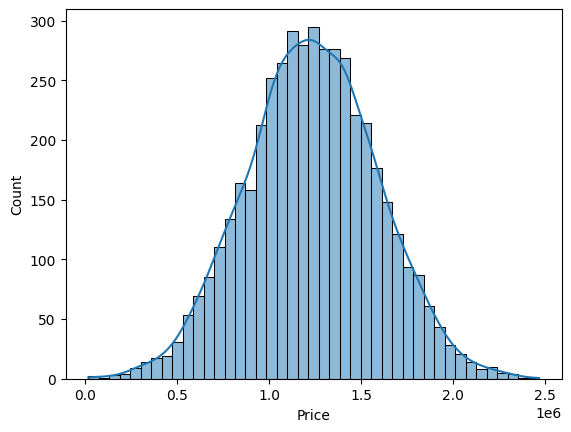

In [179]:
sns.histplot(df['Price'],kde=True)

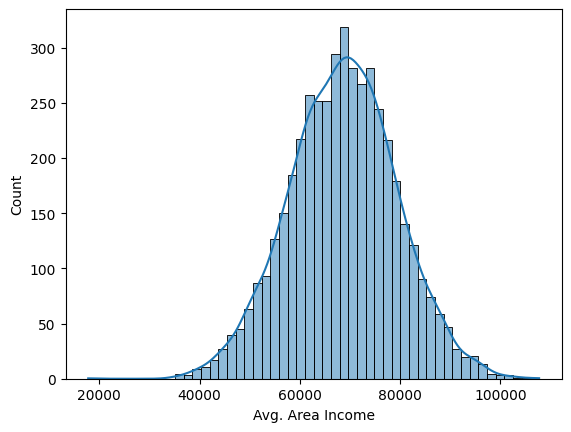

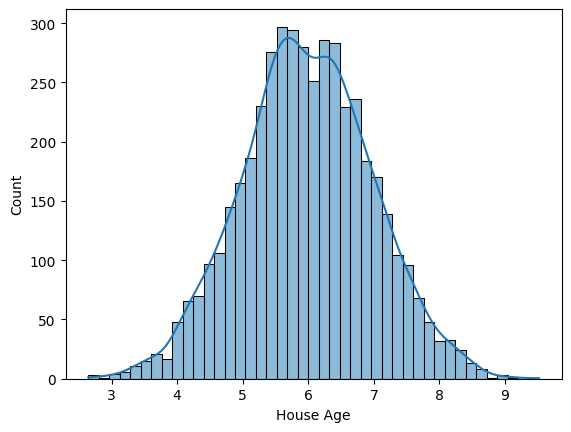

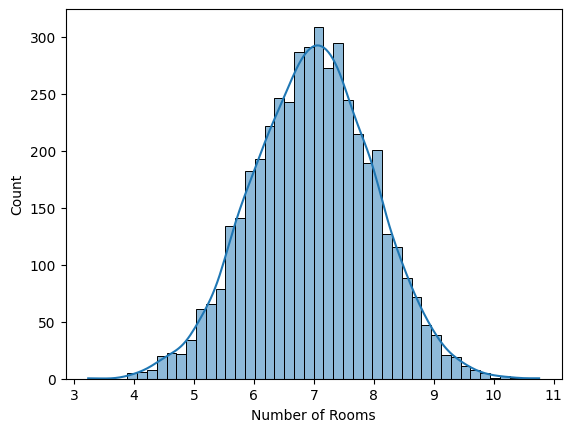

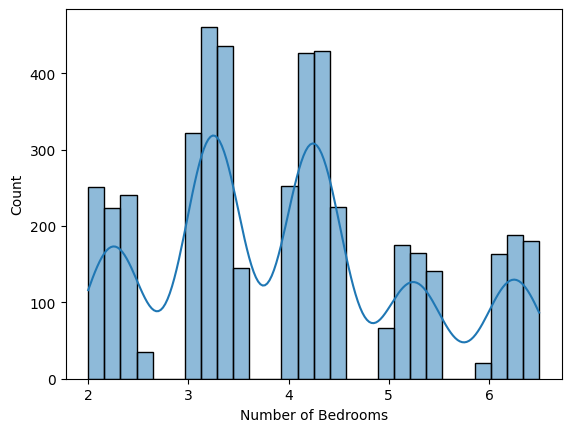

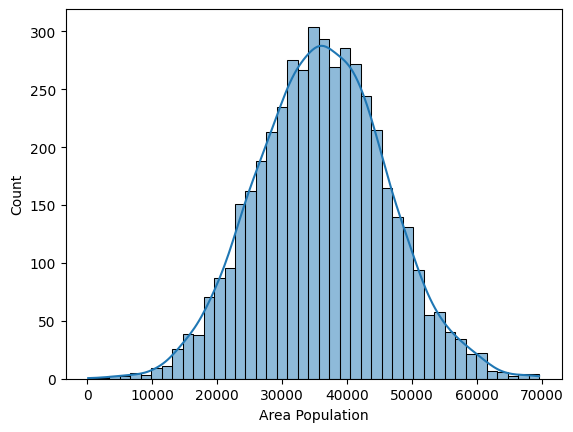

In [180]:
#make the list of all numerical exclude the price
numerical_col = ['Avg. Area Income', 'House Age', 'Number of Rooms','Number of Bedrooms', 'Area Population']
# cat_cols = df.select_dtypes(exclude='number')
for i in numerical_col:
  sns.histplot(df[i],kde=True)
  plt.show()

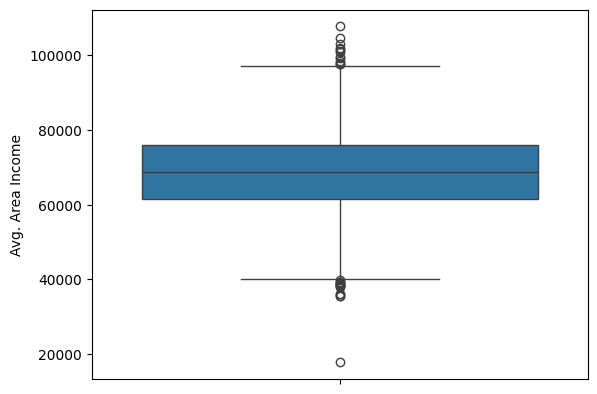

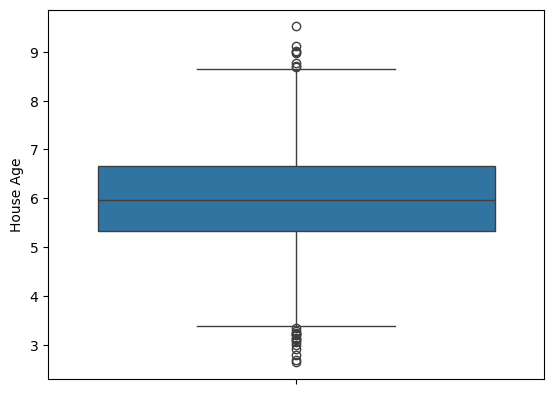

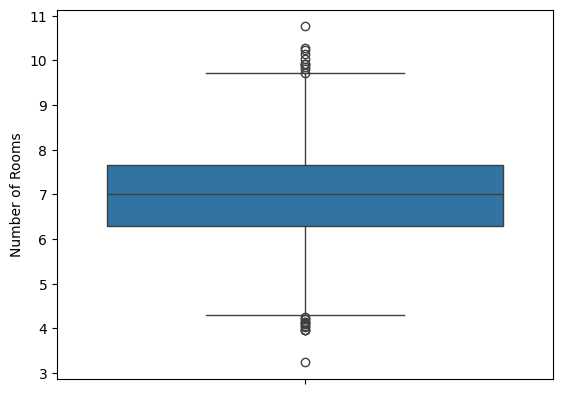

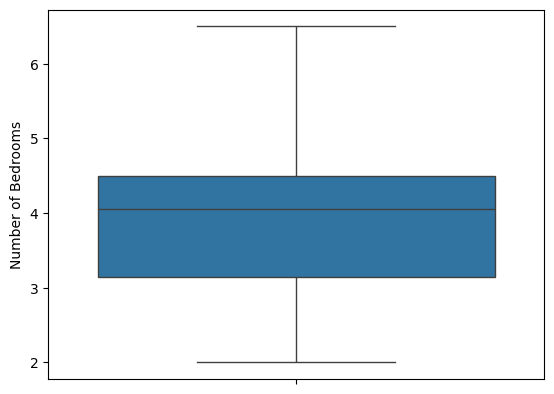

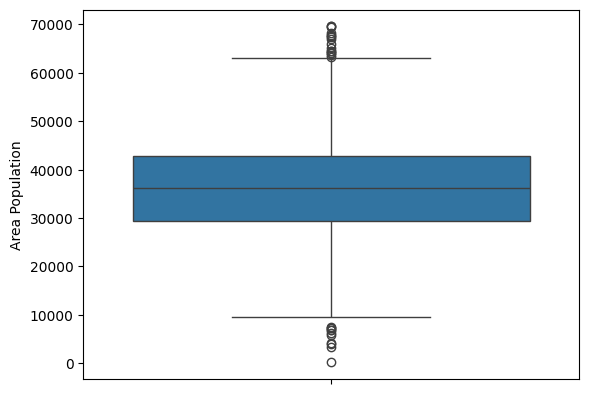

In [181]:
for i in numerical_col:
  sns.boxplot(df[i])
  plt.show()

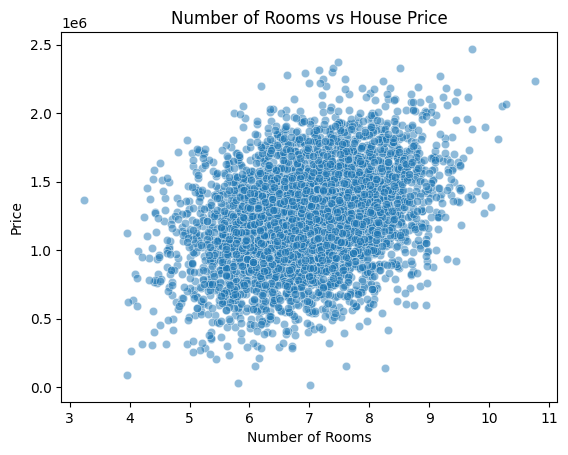

In [182]:
sns.scatterplot(
    data=df,
    x="Number of Rooms",
    y="Price",
    alpha=0.5
)

plt.title("Number of Rooms vs House Price")
plt.show()

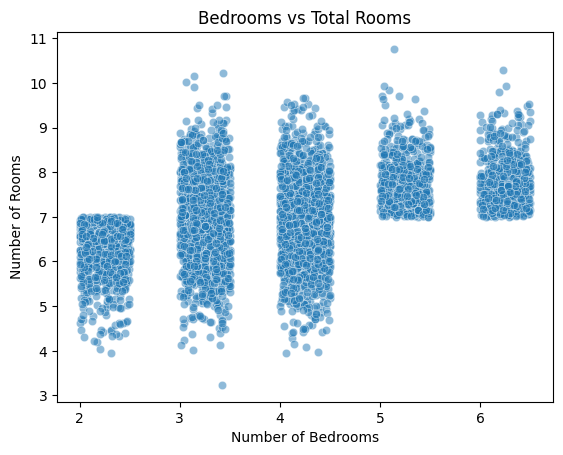

In [183]:
sns.scatterplot(
    data=df,
    x="Number of Bedrooms",
    y="Number of Rooms",
    alpha=0.5
)

plt.title("Bedrooms vs Total Rooms")
plt.show()

<Axes: >

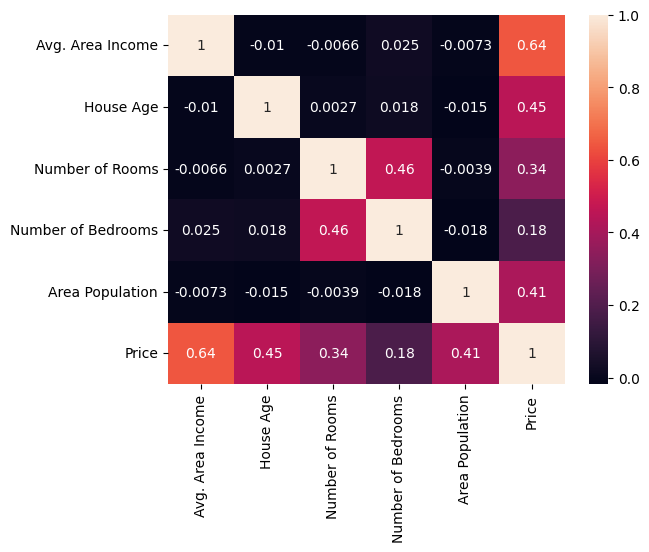

In [184]:
sns.heatmap(df.corr(numeric_only=True),annot = True)

In [185]:
#chake for the outliers
number_feacture= df.select_dtypes(include='number')
Q1 = number_feacture.quantile(0.25)
Q3 = number_feacture.quantile(0.75)
IQR = Q3 - Q1
lower_range = Q1 - 1.5*(IQR)
upper_range = Q3 + 1.5*(IQR)
outliers = (number_feacture < lower_range)|(number_feacture > upper_range)
print(outliers.sum())

Avg. Area Income      28
House Age             23
Number of Rooms       24
Number of Bedrooms     0
Area Population       27
Price                 37
dtype: int64


 # Data splitting and leakage prevention

In [186]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Price', 'Address'])
y = df['Price']

# Split into training and testing sets cleanly
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [187]:
df_copy = df.copy()

# Preprocessing for LinearRegression

In [188]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
preprocesser_lr = ColumnTransformer(
    transformers=[
        #Pipeline for numerical cols
        ('num',Pipeline([
                ('imputer',SimpleImputer(strategy='median')),
                ('Scaler',StandardScaler())
            ]),numerical_col),
    ]
)

# Preprocessing for randomforestregressor

In [189]:
preprocesser_rf = ColumnTransformer(
    transformers=[
        #Pipeline for numerical cols
        ('num',Pipeline([
                ('imputer',SimpleImputer(strategy='median'))
            ]),numerical_col),
    ]
)

# Preprocessing for Ridge Regression

In [190]:
preprocesser_rr =  ColumnTransformer(
    transformers=[
        #Pipeline for numerical cols
        ('num',Pipeline([
                ('imputer',SimpleImputer(strategy='median')),
                ('Scaler',StandardScaler())
            ]),numerical_col),
    ]
)

# Preprocessing for Lasso Regression

In [191]:
preprocesser_ls =  ColumnTransformer(
    transformers=[
        #Pipeline for numerical cols
        ('num',Pipeline([
                ('imputer',SimpleImputer(strategy='median')),
                ('Scaler',StandardScaler())
            ]),numerical_col),
    ]
)

# Preprocessing for Decision Tree Regressor

In [192]:
preprocesser_dt = ColumnTransformer(
    transformers=[
        #Pipeline for numerical cols
        ('num',Pipeline([
                ('imputer',SimpleImputer(strategy='median'))
            ]),numerical_col),
    ]
)

# Preprocessing for Gradient Boosting Regressor

In [193]:
preprocesser_gb = ColumnTransformer(
    transformers=[
        #Pipeline for numerical cols
        ('num',Pipeline([
                ('imputer',SimpleImputer(strategy='median'))
            ]),numerical_col),
    ]
)

#Model evaluation helper

In [194]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
def evaluate_model(model, X_train, X_test, y_train, y_test):

    # Train the model
    model.fit(X_train, y_train)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Evaluation metrics
    print("Training Performance")
    print("--------------------")
    print("MAE:", mean_absolute_error(y_train, y_train_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
    print("R2 Score:", r2_score(y_train, y_train_pred))

    print("\nTesting Performance")
    print("-------------------")
    print("MAE:", mean_absolute_error(y_test, y_test_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))
    print("R2 Score:", r2_score(y_test, y_test_pred))

    return model

#Baseline model ---- linear regression

In [195]:
# 1. Linear Regression
from sklearn.linear_model import LinearRegression
# 2. Ridge Regression
from sklearn.linear_model import Ridge
# 3. Lasso Regression
from sklearn.linear_model import Lasso
# 4. Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor
# 5. Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor
# 6. Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor

In [196]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocesser_lr),
    ('classifier', LinearRegression())
])
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('Scaler',
                                                                   StandardScaler())]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', LinearRegression())])

In [197]:
evaluate_model(baseline_model, X_train, X_test, y_train, y_test)

Training Performance
--------------------
MAE: 81196.59851246297
RMSE: 100864.59914272276
R2 Score: 0.9203219386818059

Testing Performance
-------------------
MAE: 81726.79216174207
RMSE: 101475.97902182426
R2 Score: 0.9150342058084733


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('Scaler',
                                                                   StandardScaler())]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', LinearRegression())])

# Ridge

In [198]:
rr_pipeline = Pipeline([
    ('preprocessor', preprocesser_rr),
    ('classifier', Ridge())
])
rr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('Scaler',
                                                                   StandardScaler())]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', Ridge())])

In [199]:
evaluate_model(rr_pipeline, X_train, X_test, y_train, y_test)

Training Performance
--------------------
MAE: 81198.65807829288
RMSE: 100864.66448272519
R2 Score: 0.9203218354510103

Testing Performance
-------------------
MAE: 81730.12184055161
RMSE: 101479.74040527153
R2 Score: 0.9150279068822053


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('Scaler',
                                                                   StandardScaler())]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', Ridge())])

# Lasso

In [200]:
ls_pipeline = Pipeline([
    ('preprocessor', preprocesser_ls),
    ('classifier', Lasso())
])
ls_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('Scaler',
                                                                   StandardScaler())]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', Lasso())])

In [201]:
evaluate_model(ls_pipeline, X_train, X_test, y_train, y_test)

Training Performance
--------------------
MAE: 81196.62117597071
RMSE: 100864.59916166091
R2 Score: 0.9203219386518855

Testing Performance
-------------------
MAE: 81726.7385703466
RMSE: 101475.9714066724
R2 Score: 0.9150342185607996


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('Scaler',
                                                                   StandardScaler())]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', Lasso())])

#DecisionTreeRegressor

In [202]:
dt_pipeline = Pipeline([
    ('preprocessor', preprocesser_dt),
    ('classifier', DecisionTreeRegressor())
])
dt_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', DecisionTreeRegressor())])

In [203]:
evaluate_model(dt_pipeline, X_train, X_test, y_train, y_test)

Training Performance
--------------------
MAE: 0.0
RMSE: 0.0
R2 Score: 1.0

Testing Performance
-------------------
MAE: 147339.7609857295
RMSE: 184505.6589525303
R2 Score: 0.7191095311657072


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', DecisionTreeRegressor())])

#RandomForestRegressor

In [204]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocesser_rf),
    ('classifier', RandomForestRegressor())
])
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', RandomForestRegressor())])

In [205]:
evaluate_model(rf_pipeline, X_train, X_test, y_train, y_test)

Training Performance
--------------------
MAE: 36118.09168998426
RMSE: 45992.88775412663
R2 Score: 0.9834330492303929

Testing Performance
-------------------
MAE: 95575.58884599322
RMSE: 120695.98832758456
R2 Score: 0.8798003254293937


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', RandomForestRegressor())])

#GradientBoostingRegressor

In [206]:
gb_pipeline = Pipeline([
    ('preprocessor', preprocesser_gb),
    ('classifier', GradientBoostingRegressor())
])
gb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', GradientBoostingRegressor())])

In [207]:
evaluate_model(gb_pipeline, X_train, X_test, y_train, y_test)

Training Performance
--------------------
MAE: 74774.60469336537
RMSE: 93207.25873148824
R2 Score: 0.9319605654828826

Testing Performance
-------------------
MAE: 89666.36389131105
RMSE: 111892.50156264828
R2 Score: 0.8966954172280653


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier', GradientBoostingRegressor())])

### Hyperparameter Tuning on Gradient Boosting Regressor
We will define a parameter grid for `n_estimators`, `learning_rate`, `max_depth`, `min_samples_split`, and `subsample`, and use `RandomizedSearchCV` with 5-fold cross-validation.

In [208]:
from sklearn.model_selection import RandomizedSearchCV

# 1. Define the parameter search space
param_distributions = {
    'classifier__n_estimators': [100, 150, 200, 300],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.15],
    'classifier__max_depth': [3, 4, 5, 6],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__subsample': [0.7, 0.8, 0.9, 1.0]
}

# 2. Initialize the RandomizedSearchCV on our existing pipeline
gb_random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring='r2',
    cv=5,
    random_state=42,
    n_jobs=-1
)

# 3. Fit the search space to find the best configuration
print("Starting Hyperparameter Tuning...")
gb_random_search.fit(X_train, y_train)

print("Best Parameters Found:")
print(gb_random_search.best_params_)


Starting Hyperparameter Tuning...
Best Parameters Found:
{'classifier__subsample': 0.7, 'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05}


Now we evaluate the performance of our final, optimized Gradient Boosting model.

In [209]:
best_gb_model = gb_random_search.best_estimator_
evaluate_model(best_gb_model, X_train, X_test, y_train, y_test)

Training Performance
--------------------
MAE: 71672.08470660754
RMSE: 88898.05401656943
R2 Score: 0.9381064014855233

Testing Performance
-------------------
MAE: 85872.00607219645
RMSE: 107018.09810632253
R2 Score: 0.9054999412946139


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Avg. Area Income',
                                                   'House Age',
                                                   'Number of Rooms',
                                                   'Number of Bedrooms',
                                                   'Area Population'])])),
                ('classifier',
                 GradientBoostingRegressor(learning_rate=0.05, n_estimators=300,
                                           subsample=0.7))])

### Feature Importance of the Tuned Gradient Boosting Model
We extract and plot the feature importances from our best estimator (`best_gb_model`) to see which features contribute the most to the predictions.

/tmp/ipykernel_993/41370066.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


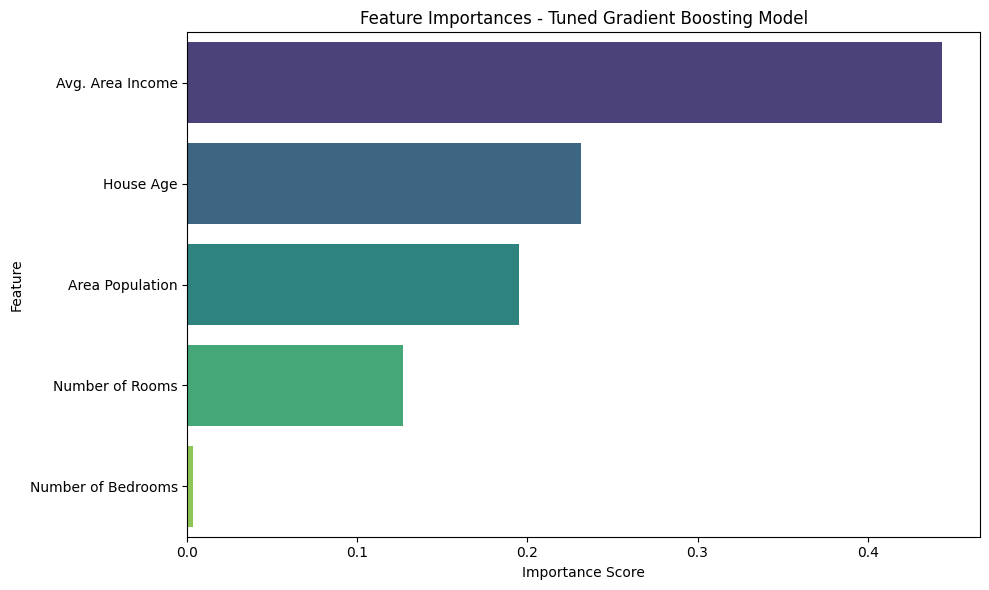

In [211]:

# 1. Extract feature importances from the classifier step of our pipeline
importances = best_gb_model.named_steps['classifier'].feature_importances_

# 2. Map importances to the input numerical columns
feature_importance_df = pd.DataFrame({
    'Feature': numerical_col,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Feature Importances - Tuned Gradient Boosting Model')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### Saving the Final Model


In [212]:
import joblib

# Save the complete pipeline to a file
model_filename = 'final_house_price_gb_model.joblib'
joblib.dump(best_gb_model, model_filename)

print(f"Success! Your final model pipeline has been saved as: {model_filename}")
print("You can download this file from the left files panel in Colab and load it in production.")

Success! Your final model pipeline has been saved as: final_house_price_gb_model.joblib
You can download this file from the left files panel in Colab and load it in production.
